<a href="https://colab.research.google.com/github/BioML-UGent/Advanced-AI-for-Bioinformatics/blob/main/07_complex_prediction/07_Complex_Prediction_Problem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PC lab 7: Multi-target prediction

In this PC lab, we predict how strongly kinase inhibitors bind to kinases. Every data point is a **(drug, protein) pair** with a continuous binding affinity, so we can see the data as a large drug × protein matrix in which most entries are missing. In **part 1**, we fill in the missing entries of this matrix, for drugs and proteins that we have seen during training: first with the singular value decomposition (SVD), then with a **two-branch neural network**. In **part 2**, we predict affinities for **new drugs**, which requires features of the drugs and proteins.

**Learning goals**
- Recognize the different prediction settings for drug-protein pairs, and how they determine the train/test split
- Complete a matrix with missing values with a truncated SVD, and choose its rank on a validation set
- Build and train a two-branch neural network with `nn.Embedding`
- Understand why ID embeddings cannot be used for new drugs, and use side information (features) instead
- Always compare a model with a simple baseline

## 0 Setup

The first cell installs RDKit, a chemistry toolkit. The other cells download the data and load the training functions from PC lab 2.

We use the [KIBA benchmark](https://researchportal.helsinki.fi/en/datasets/kiba-a-benchmark-dataset-for-drug-target-prediction) as provided by [Therapeutics Data Commons (TDC)](https://tdcommons.ai/multi_pred_tasks/dti/). The original KIBA dataset contains 52,498 compounds and 467 kinases; the TDC version is filtered to the 2,068 drugs and 229 kinases with the most measurements. We download the TDC data file directly (97 MB).

In [ ]:
!pip install -q rdkit

In [ ]:
import copy
import os

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import requests
from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils.extmath import randomized_svd
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

torch.manual_seed(42)
np.random.seed(42)

# KIBA as provided by TDC, stored on Harvard Dataverse
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/kiba.tab"):
    response = requests.get("https://dataverse.harvard.edu/api/access/datafile/5255037", timeout=300)
    response.raise_for_status()
    with open("data/kiba.tab", "wb") as f:
        f.write(response.content)

df = pd.read_csv("data/kiba.tab", sep="\t")
df = df.rename(columns={"ID1": "Drug_ID", "X1": "Drug", "ID2": "Target_ID", "X2": "Target"})
# columns: Drug_ID, Drug (SMILES), Target_ID, Target (amino acid sequence), Y (affinity)

In [ ]:
# Training functions from PC lab 2, adapted for regression: the loss is the MSE, and there is no accuracy.
# A batch can now contain several inputs: it is a tuple (input 1, input 2, ..., targets),
# and the model gets all inputs: model(*inputs).
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    batch_losses = []
    for *inputs, y_batch in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(*inputs), y_batch)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    return batch_losses


def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, n = 0.0, 0
    with torch.no_grad():
        for *inputs, y_batch in loader:
            total_loss += loss_fn(model(*inputs), y_batch).item() * len(y_batch)
            n += len(y_batch)
    return total_loss / n


def fit_early_stopping(model, optimizer, train_loader, val_loader, n_epochs, patience):
    """Train until the validation loss has not improved for `patience` epochs; restore the best weights."""
    loss_fn = nn.MSELoss()
    history = {"train_loss": [], "val_loss": []}
    best_val_loss, best_epoch, best_state = float("inf"), 0, None
    for epoch in range(1, n_epochs + 1):
        batch_losses = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(np.mean(batch_losses))
        history["val_loss"].append(val_loss)
        if val_loss < best_val_loss:
            best_val_loss, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())
        elif epoch - best_epoch >= patience:
            break
    model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch
    return history


def plot_history(history, title=""):
    """Plot the training and validation loss per epoch, and mark the epoch with the best validation loss."""
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    plt.plot(epochs, history["train_loss"], label="training loss")
    plt.plot(epochs, history["val_loss"], label="validation loss")
    plt.axvline(history["best_epoch"], color="gray", linestyle="--", label="best epoch")
    plt.xlabel("epoch")
    plt.ylabel("MSE")
    plt.title(title)
    plt.legend()
    plt.show()

## 1 The data and the prediction settings

Our task is regression: given a drug-protein pair, predict its affinity `Y`. In the dataframe, every row is one measured pair. We can also arrange the affinities in a matrix with one row per drug and one column per protein. Most entries of this matrix are missing: those pairs were never measured.

In [ ]:
display(df.head())

n_drugs, n_prots = df["Drug_ID"].nunique(), df["Target_ID"].nunique()
print(f"{n_drugs} drugs, {n_prots} proteins, {len(df)} measured pairs")
print(f"fraction of the drug x protein matrix that is observed: {len(df) / (n_drugs * n_prots):.3f}")
print(f"measured proteins per drug: median {df.groupby('Drug_ID').size().median():.0f}")
print(f"measured drugs per protein: median {df.groupby('Target_ID').size().median():.0f}")
print(f"affinity: mean {df['Y'].mean():.2f}, variance {df['Y'].var():.3f}")

plt.hist(df["Y"], bins=100)
plt.xlabel("affinity (KIBA score)")
plt.ylabel("number of pairs")
plt.show()

Depending on the goal, there are different **prediction settings**. With the drugs as rows (instances) and the proteins as columns (targets), the figure below shows four of them. The green entries are the training data.
- **Setting A**: predict the missing entries for drugs *and* proteins that are both in the training data. This is a **matrix completion** problem, as in a recommender system.
- **Setting B**: predict the affinities of a **new drug** (a new row) for the known proteins.
- **Setting C**: predict the affinities of the known drugs for a **new protein** (a new column).
- **Setting D**: predict the affinity of a new drug for a new protein.

The setting determines how we have to split the data into a training, validation and test set, and which models can be used at all.

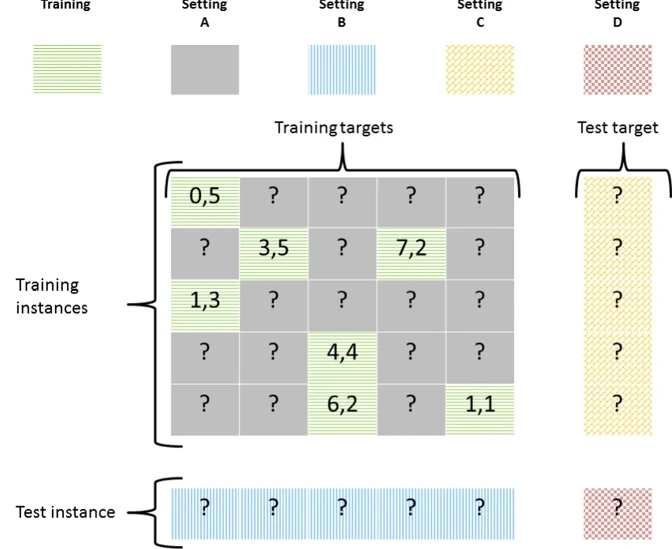


<div class="alert alert-success">

<b>EXERCISE 0 (THINK): which setting?</b>

a) A pharmaceutical company has synthesized a new kinase inhibitor, and wants to know which of the 229 kinases it binds. Which setting is this? And if a research group wants to know which of the known inhibitors bind a kinase that was not in the data before?

b) For Setting A, we can split the measured pairs at random into a training and a test set. Why does such a test set give a too optimistic estimate for Setting B? How should we split the data for Setting B?

</div>

**Your answer:**

# Part 1: Setting A, matrix completion

## 2 Matrix factorization with the SVD

For Setting A, a random split of the pairs is fine: `random_split` puts 70% of the pairs in the training set, 10% in the validation set and 20% in the test set. Because every drug and protein has many measurements, they all also appear in the training set.

In [ ]:
def random_split(df, seed=42, frac=(0.7, 0.1, 0.2)):
    """Random split of the pairs into a training, validation and test set (as in TDC)."""
    test = df.sample(frac=frac[2], random_state=seed)
    train_val = df.drop(test.index)
    val = train_val.sample(frac=frac[1] / (1 - frac[2]), random_state=1)
    train = train_val.drop(val.index)
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)


train_df, val_df, test_df = random_split(df)
print(f"train {len(train_df)}, validation {len(val_df)}, test {len(test_df)} pairs")
print("test drugs that are not in the training set:", len(set(test_df["Drug_ID"]) - set(train_df["Drug_ID"])))
print("test proteins that are not in the training set:", len(set(test_df["Target_ID"]) - set(train_df["Target_ID"])))

**A baseline.** Before we train anything, we need to know what a good MSE is. The simplest possible model ignores the drug and the protein, and always predicts the mean affinity of the training set. Its MSE is close to the variance of the affinities. Every model in this PC lab should do better than this.

In [ ]:
mu = train_df["Y"].mean()
print(f"baseline (always predict the training mean {mu:.2f}): test MSE {np.mean((test_df['Y'] - mu) ** 2):.3f}")

**The interaction matrix.** We give every drug and every protein an index, and put the training affinities in a matrix `M_train`. The SVD needs a complete matrix, so we have to fill in the missing entries. We first try the simplest option: fill them with zeros.

In [ ]:
drugs = sorted(df["Drug_ID"].unique())
prots = sorted(df["Target_ID"].unique())
drug_to_idx = {d: i for i, d in enumerate(drugs)}
prot_to_idx = {p: i for i, p in enumerate(prots)}


def to_index(df):
    """Row (drug) and column (protein) indices of the pairs in df."""
    return df["Drug_ID"].map(drug_to_idx).values, df["Target_ID"].map(prot_to_idx).values


def matrix_mse(M_pred, df):
    """MSE of the predictions in the matrix M_pred for the pairs in df."""
    rows, cols = to_index(df)
    return np.mean((M_pred[rows, cols] - df["Y"].values) ** 2)


train_rows, train_cols = to_index(train_df)
M_train = np.zeros((len(drugs), len(prots)))
M_train[train_rows, train_cols] = train_df["Y"].values
print("training matrix shape:", M_train.shape)

A **truncated SVD** with $k$ components approximates the matrix as $U S V^\top$, where $U$ has shape (drugs × $k$), $S$ is a diagonal matrix with the $k$ largest singular values, and $V^\top$ has shape ($k$ × proteins). Every drug gets a $k$-dimensional vector (a row of $U$), every protein too (a column of $V^\top$), and the predicted affinity of a pair is a weighted dot product of the two. Run the cell below, which uses $k = 64$.

In [ ]:
k = 64
U, S, VT = randomized_svd(M_train, n_components=k, random_state=42)
print("U:", U.shape, " S:", S.shape, " VT:", VT.shape)

M_recon = U @ np.diag(S) @ VT
print(f"zeros for the missing values, k={k}: train MSE {matrix_mse(M_recon, train_df):.3f}, "
      f"test MSE {matrix_mse(M_recon, test_df):.3f}")

<div class="alert alert-success">

<b>EXERCISE 1: matrix completion with the SVD</b>

a) <b>THINK:</b> The test MSE above is far worse than the baseline, and even the training MSE is bad. Why does filling in the missing values with zeros go so wrong? Hint: look at the histogram of the affinities, and at the fraction of the matrix that is observed.

b) A better choice is to fill in the missing entries with the mean training affinity `mu`. Equivalently, we **center** the matrix: subtract `mu` from the observed entries and put 0 in the missing ones, compute the SVD, and add `mu` back to the reconstruction. Do this for k in `[2, 4, 8, 16, 32, 64]`, and print the training and validation MSE for every k.

c) Choose the k with the lowest validation MSE, and compute its test MSE. <b>THINK:</b> How do the training and the validation MSE change with k? Why do we choose k with the validation set and not with the test set?

</div>

**Your answer:**

b)

In [ ]:
######## YOUR CODE HERE #########
M_centered = ...  # the training matrix with mu subtracted from the observed entries, and 0 in the missing entries

val_mse = {}
for k in [2, 4, 8, 16, 32, 64]:
    # truncated SVD of M_centered with k components, reconstruct the matrix, and add mu back
    M_recon = ...
    val_mse[k] = matrix_mse(M_recon, val_df)
    print(f"k={k:2d}: train MSE {matrix_mse(M_recon, train_df):.3f}, val MSE {val_mse[k]:.3f}")
#################################

c)

In [ ]:
######## YOUR CODE HERE #########
best_k = ...   # the k with the lowest validation MSE
M_recon = ...  # the reconstruction with best_k components (plus mu)
#################################

print(f"best k = {best_k}: test MSE {matrix_mse(M_recon, test_df):.3f}")

**Your answer:**

## 3 A two-branch neural network

Filling in the missing values with the mean is a crude fix: the SVD still tries to reproduce all these made-up values. A neural network can instead be trained on the observed pairs only. In a **two-branch network**, every drug index and every protein index is mapped to a trainable embedding vector with `nn.Embedding`. The two embeddings are concatenated and passed through an MLP that outputs the predicted affinity:

$$\hat{y}_{dp} = f(\mathbf{e}_d, \mathbf{e}_p),$$

where $\mathbf{e}_d$ and $\mathbf{e}_p$ are the embeddings of drug $d$ and protein $p$. The embeddings and the MLP are trained together by minimizing the MSE on the observed pairs.

The cell below makes the data loaders. Every batch is a tuple `(drug indices, protein indices, affinities)`, so the training functions call `model(drug indices, protein indices)`.

The affinities are around 11.7, while a freshly initialized network outputs values around 0. Just like the inputs (see the normalization in PC lab 2), networks train much better when the targets are on a small scale. We therefore **center** the targets: the datasets contain the affinities minus the mean training affinity `mu`, and the network predicts this difference. This does not change the MSE, because a prediction and its target are shifted by the same amount.

In [ ]:
def make_id_dataset(df, mu):
    """Dataset with the drug indices, the protein indices and the centered affinities (Y - mu) of the pairs in df."""
    rows, cols = to_index(df)
    return TensorDataset(torch.tensor(rows), torch.tensor(cols), torch.tensor(df["Y"].values - mu, dtype=torch.float32))


train_loader = DataLoader(make_id_dataset(train_df, mu), batch_size=1024, shuffle=True)
val_loader = DataLoader(make_id_dataset(val_df, mu), batch_size=1024, shuffle=False)
test_loader = DataLoader(make_id_dataset(test_df, mu), batch_size=1024, shuffle=False)

d_batch, p_batch, y_batch = next(iter(train_loader))
print(d_batch.shape, p_batch.shape, y_batch.shape)

<div class="alert alert-success">

<b>EXERCISE 2: a two-branch network</b>

a) Complete `TwoBranchNN` below: an `nn.Embedding` of dimension `emb_dim` for the drugs and one for the proteins, and `self.mlp`, an `nn.Sequential` with one hidden layer of `hidden_dim` units (ReLU) that maps the concatenated embeddings to one output. `forward` returns a 1D tensor with the predicted affinities.

b) Train a `TwoBranchNN` with `emb_dim=64` and `hidden_dim=64` with Adam (learning rate 0.001): use `fit_early_stopping` with at most 50 epochs and patience 5. Plot the learning curves with `plot_history`, and compute the test MSE with `evaluate`. Compare with the baseline and with the SVD.

</div>

a)

In [ ]:
class TwoBranchNN(nn.Module):
    def __init__(self, num_drugs, num_prots, emb_dim=64, hidden_dim=64):
        super().__init__()
        ######## YOUR CODE HERE #########
        self.drug_emb = ...  # embedding for the drugs
        self.prot_emb = ...  # embedding for the proteins
        self.mlp = ...       # nn.Sequential: Linear (2 * emb_dim -> hidden_dim) -> ReLU -> Linear (hidden_dim -> 1)
        #################################

    def forward(self, d_idx, p_idx):
        ######## YOUR CODE HERE #########
        # look up the embeddings, concatenate them, pass them through the MLP,
        # and return a 1D tensor (hint: .squeeze(1))
        return ...
        #################################


print(TwoBranchNN(len(drugs), len(prots))(d_batch, p_batch).shape)  # should be (1024,)

b)

In [ ]:
torch.manual_seed(0)
######## YOUR CODE HERE #########
model = ...
optimizer = ...
history = ...
#################################

plot_history(history, "two-branch network, Setting A")
print(f"best epoch {history['best_epoch']}: test MSE {evaluate(model, test_loader, nn.MSELoss()):.3f}")

**Your answer:**

# Part 2: Setting B, new drugs

## 4 Adding features

In practice, we often want to predict affinities for a **new** compound, for example one that was just synthesized. This is Setting B. The function `cold_split` below therefore splits the **drugs** (not the pairs) into a training, validation and test set, and puts every pair in the set of its drug. The drugs in the test set are then not in the training set.

In this setting, the proteins are known, so there is a second baseline: predict the mean training affinity of the protein, whatever the drug.

In [ ]:
def cold_split(df, column, seed=42, frac=(0.7, 0.1, 0.2)):
    """Split the values of `column` (e.g. the drugs), and put every pair in the set of its value (as in TDC)."""
    entities = df[column].drop_duplicates()
    test_entities = entities.sample(frac=frac[2], random_state=seed)
    val_entities = entities.drop(test_entities.index).sample(frac=frac[1] / (1 - frac[2]), random_state=seed)
    test = df[df[column].isin(test_entities)]
    val = df[df[column].isin(val_entities)]
    train = df[~df[column].isin(test_entities) & ~df[column].isin(val_entities)]
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)


cold_train_df, cold_val_df, cold_test_df = cold_split(df, "Drug_ID")
print(f"train {len(cold_train_df)}, validation {len(cold_val_df)}, test {len(cold_test_df)} pairs")
print("test drugs that are also in the training set:", len(set(cold_test_df["Drug_ID"]) & set(cold_train_df["Drug_ID"])))

cold_mu = cold_train_df["Y"].mean()
print(f"baseline 1 (always predict the training mean): test MSE {np.mean((cold_test_df['Y'] - cold_mu) ** 2):.3f}")
prot_mean = cold_train_df.groupby("Target_ID")["Y"].mean()
print(f"baseline 2 (predict the mean affinity of the protein): "
      f"test MSE {np.mean((cold_test_df['Y'] - cold_test_df['Target_ID'].map(prot_mean)) ** 2):.3f}")

A model that only knows drug IDs cannot say anything about a new drug. We therefore add **side information**: features that we can compute for any drug or protein.
- For every drug, a 512-bit **Morgan fingerprint** of its SMILES string: every bit indicates whether a certain substructure is present in the molecule.
- For every protein, its **amino acid composition**: the fraction of each of the 20 amino acids in its sequence. We use fractions rather than counts: the counts mostly reflect the length of the protein and go up to several hundreds, while the fingerprint bits are 0 or 1.

The cell below computes the features and makes the data loaders. Every batch is now a tuple `(drug indices, protein indices, drug features, protein features, affinities)`. As in section 3, the affinities are centered, now with the mean training affinity `cold_mu` of this split.

In [ ]:
drug_smiles = df.drop_duplicates("Drug_ID").set_index("Drug_ID")["Drug"]
prot_seqs = df.drop_duplicates("Target_ID").set_index("Target_ID")["Target"]

fp_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=512)
amino_acids = "ACDEFGHIKLMNPQRSTVWY"


def morgan_fp(smiles):
    """512-bit Morgan fingerprint (radius 2) of a molecule."""
    return fp_generator.GetFingerprintAsNumPy(Chem.MolFromSmiles(smiles))


def aa_composition(seq):
    """Fraction of each of the 20 amino acids in a protein sequence."""
    counts = np.array([seq.count(aa) for aa in amino_acids])
    return counts / counts.sum()


# one row per drug / protein, in the order of drug_to_idx and prot_to_idx
drug_feats = torch.tensor(np.stack([morgan_fp(drug_smiles[d]) for d in drugs]), dtype=torch.float32)
prot_feats = torch.tensor(np.stack([aa_composition(prot_seqs[p]) for p in prots]), dtype=torch.float32)
print("drug features:", drug_feats.shape, " protein features:", prot_feats.shape)


def make_feature_dataset(df, mu):
    """Dataset with the drug and protein indices, their features, and the centered affinities (Y - mu) of the pairs in df."""
    rows, cols = to_index(df)
    d_idx, p_idx = torch.tensor(rows), torch.tensor(cols)
    return TensorDataset(d_idx, p_idx, drug_feats[d_idx], prot_feats[p_idx], torch.tensor(df["Y"].values - mu, dtype=torch.float32))


cold_train_loader = DataLoader(make_feature_dataset(cold_train_df, cold_mu), batch_size=256, shuffle=True)
cold_val_loader = DataLoader(make_feature_dataset(cold_val_df, cold_mu), batch_size=1024, shuffle=False)
cold_test_loader = DataLoader(make_feature_dataset(cold_test_df, cold_mu), batch_size=1024, shuffle=False)

<div class="alert alert-success">

<b>EXERCISE 3: predicting affinities for new drugs</b>

a) Complete `TwoBranchWithFeatures` below. The drug branch gets the fingerprint and, if `use_drug_id=True`, also a drug ID embedding (concatenated to the fingerprint). Likewise, the protein branch gets the amino acid composition and, if `use_prot_id=True`, also a protein ID embedding. Each branch is an `nn.Sequential` with two layers of `hidden_dim` units (ReLU). The outputs of the two branches are concatenated and passed through `self.head`, an `nn.Sequential` with two hidden layers of `hidden_dim` units (ReLU) and one output.

b) Train two models on `cold_train_loader`: one **with** and one **without** the drug ID embedding (both with the protein ID embedding). Use Adam (learning rate 0.001) and `fit_early_stopping` with at most 30 epochs and patience 5, with `cold_val_loader` as validation set. Plot the learning curves, compute the test MSE, and compare with the two baselines.

c) <b>THINK:</b> Why does the drug ID embedding hurt in this setting? Hint: which embedding vector does the model use for a drug in the test set, and was it ever updated during training? Why can we keep the protein ID embedding?

d) <b>THINK:</b> Compare the best test MSE with the second baseline, and with the model of section 3 (Setting A). Does the model learn much from the fingerprints of drugs it has never seen? Why could this work so well for the drugs in KIBA? Hint: kinase inhibitors are usually developed in series of very similar compounds. What would you change in the split to get a more realistic estimate for truly novel compounds?

</div>

a)

In [ ]:
class TwoBranchWithFeatures(nn.Module):
    def __init__(self, num_drugs, num_prots, drug_feat_dim=512, prot_feat_dim=20,
                 emb_dim=64, hidden_dim=128, use_drug_id=True, use_prot_id=True):
        super().__init__()
        self.use_drug_id = use_drug_id
        self.use_prot_id = use_prot_id
        drug_in = drug_feat_dim + (emb_dim if use_drug_id else 0)  # input size of the drug branch
        prot_in = prot_feat_dim + (emb_dim if use_prot_id else 0)  # input size of the protein branch
        ######## YOUR CODE HERE #########
        # the ID embeddings (only if they are used)


        self.drug_branch = ...  # drug_in -> hidden_dim -> ReLU -> hidden_dim -> ReLU
        self.prot_branch = ...  # prot_in -> hidden_dim -> ReLU -> hidden_dim -> ReLU
        self.head = ...         # 2 * hidden_dim -> hidden_dim -> ReLU -> hidden_dim -> ReLU -> 1
        #################################

    def forward(self, d_idx, p_idx, d_feat, p_feat):
        ######## YOUR CODE HERE #########
        # concatenate the ID embeddings to the features (only if they are used),
        # pass both through their branch, concatenate the outputs, and pass them through the head
        return ...
        #################################


batch = next(iter(cold_train_loader))
print(TwoBranchWithFeatures(len(drugs), len(prots))(*batch[:-1]).shape)  # should be (256,)
print(TwoBranchWithFeatures(len(drugs), len(prots), use_drug_id=False)(*batch[:-1]).shape)  # should be (256,)

b)

In [ ]:
for use_drug_id in [True, False]:
    name = "with drug ID embedding" if use_drug_id else "without drug ID embedding"
    torch.manual_seed(0)
    ######## YOUR CODE HERE #########
    model = ...
    optimizer = ...
    history = ...
    #################################
    plot_history(history, name)
    print(f"{name}: best epoch {history['best_epoch']}, "
          f"test MSE {evaluate(model, cold_test_loader, nn.MSELoss()):.3f}")

**Your answer:**

### Optional extra exercises

### Extra 1: new proteins (Setting C)

<div class="alert alert-success">

<b>EXTRA 1: new proteins</b>

With `cold_split(df, "Target_ID")`, we hold out proteins instead of drugs. Make data loaders for this split with `make_feature_dataset` (center with the mean training affinity of this split), and train a `TwoBranchWithFeatures` with the ID embeddings that make sense in this setting, in the same way as in exercise 3. Compare its test MSE with the mean baseline, and with a baseline that predicts the mean affinity of the drug. <b>THINK:</b> Why is this setting so hard for this dataset? Hint: how many different proteins are there in the training set, and how much does the amino acid composition tell about a kinase?

</div>

In [ ]:
######## YOUR CODE HERE #########

#################################

**Your answer:**